<a href="https://colab.research.google.com/github/adornkjoshy30-pixel/Healthcare-Workflow-Intelligence/blob/main/Week_13_NO_Practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [ ]:
df = pd.read_csv("/content/no.csv")
df

,Temprature,sale of Ice cream
0,28,56
1,33,66
2,27,69
3,26,52
4,35,96
5,35,70
6,35,70
7,30,50
8,33,69
9,25,50


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Temprature         13 non-null     int64
 1   sale of Ice cream  13 non-null     int64
dtypes: int64(2)
memory usage: 340.0 bytes


In [ ]:
df.describe()

,Temprature,sale of Ice cream
count,13.000000,13.000000
mean,30.307692,63.230769
std,3.591300,12.497692
min,25.000000,50.000000
25%,27.000000,54.000000
50%,30.000000,60.000000
75%,33.000000,69.000000
max,35.000000,96.000000


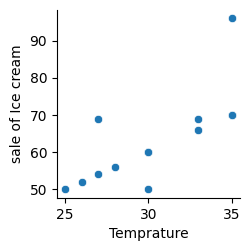

In [ ]:
sns.pairplot(df,x_vars=['Temprature'],y_vars=['sale of Ice cream'],kind ='scatter')
plt.xlabel('Temprature')
plt.ylabel('sale of Ice cream')
plt.show()

In [ ]:
x = df['Temprature']
y = df['sale of Ice cream']

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=0)

In [ ]:
x_train.shape


(9,)

In [ ]:
y_train.shape

(9,)

In [ ]:
x_train = x_train.values.reshape(-1,1)

In [ ]:
x_train.shape

(9, 1)

In [ ]:
x_test = x_test.values.reshape(-1,1)

In [ ]:
x_test.shape

(4, 1)

In [ ]:
#model creation


model  = LinearRegression()
model.fit(x_train,y_train)

predicted = model.predict(x_test)



In [ ]:
r2 = r2_score(y_test,predicted)

print(r2)


0.16880489937757603


In [ ]:
mse = mean_squared_error(y_test,predicted)
print(mse)

180.16153805991038


In [ ]:
df.rename(columns={'sale of Ice cream':'sale'}, inplace=True)

In [ ]:
import statsmodels.formula.api as smf
model = smf.ols(formula='sale ~ Temprature', data=df)

In [ ]:
result = model.fit()


In [ ]:
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                   sale   R-squared:                       0.533
Model:                            OLS   Adj. R-squared:                  0.490
Method:                 Least Squares   F-statistic:                     12.54
Date:                Sat, 09 May 2026   Prob (F-statistic):            0.00463
Time:                        12:23:09   Log-Likelihood:                -45.814
No. Observations:                  13   AIC:                             95.63
Df Residuals:                      11   BIC:                             96.76
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -13.7435     21.881     -0.628      0.5